<a href="https://colab.research.google.com/github/kaylatucker/CS690_Capstone/blob/main/03_notebooks/12_final_visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Final Business Visualizations

## Figure 1 — Seller Revenue Concentration

**Business question:** How concentrated are marketplace sales among Olist sellers?

**Method:** Rank sellers by total item-price sales and calculate the cumulative percentage of marketplace sales generated by the top sellers.

**Purpose:** Determine whether marketplace sales are concentrated among a relatively small group of sellers.

**Note:** Sales represent item-price revenue, not seller profit or total customer payments.


In [1]:
!git clone https://github.com/kaylatucker/CS690_Capstone.git

Cloning into 'CS690_Capstone'...
remote: Enumerating objects: 319, done.
remote: Counting objects: 100% (279/279), done.
remote: Compressing objects: 100% (267/267), done.
remote: Total 319 (delta 162), reused 23 (delta 11), pack-reused 40 (from 4)
Receiving objects: 100% (319/319), 85.89 MiB | 18.07 MiB/s, done.
Resolving deltas: 100% (164/164), done.
Updating files: 100% (49/49), done.


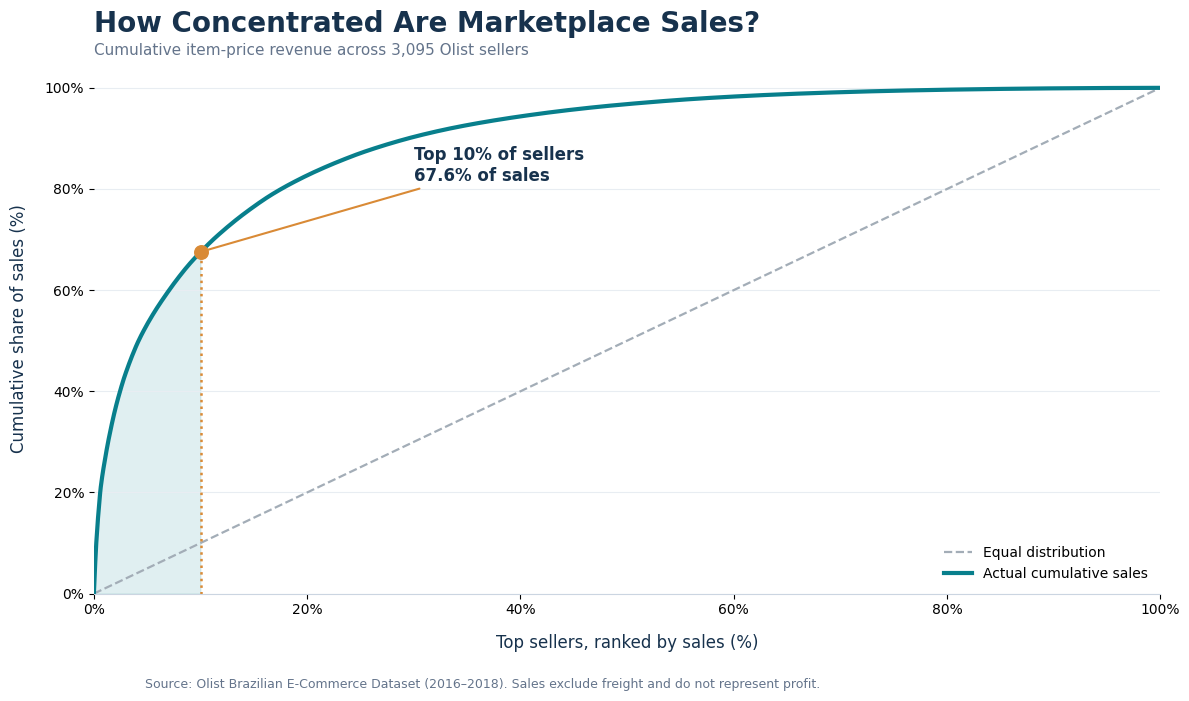

Sellers analyzed: 3,095
Total item-price sales: R$13,591,643.70
Top 10% seller sales share: 67.56%
Top 20% seller sales share: 82.69%
Saved figures to: /content/CS690_Capstone/06_outputs/figures


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.ticker import PercentFormatter

# Paths
ROOT = Path("/content/CS690_Capstone")
DATA = ROOT / "02_data/processed/seller_metrics.csv"
OUTPUT = ROOT / "06_outputs/figures"
OUTPUT.mkdir(parents=True, exist_ok=True)

# Load validated seller data
sellers = pd.read_csv(DATA)

sales = pd.to_numeric(
    sellers["seller_total_sales"], errors="coerce"
).dropna()

assert len(sales) > 0, "No valid seller sales found."
assert (sales >= 0).all(), "Unexpected negative sales values."
assert sales.sum() > 0, "Total sales must be positive."

# Rank sellers by item-price revenue
sales = sales.sort_values(ascending=False).reset_index(drop=True)

n = len(sales)
total_sales = sales.sum()

x = np.arange(1, n + 1) / n * 100
y = sales.cumsum() / total_sales * 100

n10 = int(np.ceil(n * 0.10))
n20 = int(np.ceil(n * 0.20))

share10 = sales.iloc[:n10].sum() / total_sales * 100
share20 = sales.iloc[:n20].sum() / total_sales * 100

# Professional figure
fig, ax = plt.subplots(figsize=(12, 7))
fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")

navy = "#17324D"
teal = "#087F8C"
orange = "#D98A36"

# Equal-distribution reference
ax.plot(
    [0, 100], [0, 100],
    color="#A3ADB7", linestyle="--",
    linewidth=1.6, label="Equal distribution"
)

# Cumulative sales concentration
ax.plot(
    np.r_[0, x], np.r_[0, y],
    color=teal, linewidth=3,
    label="Actual cumulative sales"
)

# Highlight top 10%
ax.fill_between(
    np.r_[0, x], np.r_[0, y],
    where=np.r_[0, x] <= 10,
    color=teal, alpha=0.12
)

ax.scatter(
    [10], [share10],
    s=95, color=orange, zorder=5
)

ax.plot(
    [10, 10], [0, share10],
    color=orange, linestyle=":",
    linewidth=1.8
)

ax.annotate(
    f"Top 10% of sellers\n{share10:.1f}% of sales",
    xy=(10, share10),
    xytext=(30, min(91, share10 + 14)),
    fontsize=12,
    fontweight="bold",
    color=navy,
    arrowprops=dict(
        arrowstyle="-",
        color=orange,
        linewidth=1.5
    )
)

# Titles
ax.set_title(
    "How Concentrated Are Marketplace Sales?",
    fontsize=20, fontweight="bold",
    color=navy, loc="left", pad=22
)

ax.text(
    0, 1.015,
    f"Cumulative item-price revenue across {n:,} Olist sellers",
    transform=ax.transAxes,
    fontsize=11, color="#64748B"
)

ax.set_xlabel(
    "Top sellers, ranked by sales (%)",
    fontsize=12, color=navy, labelpad=12
)
ax.set_ylabel(
    "Cumulative share of sales (%)",
    fontsize=12, color=navy, labelpad=12
)

ax.set_xlim(0, 100)
ax.set_ylim(0, 105)

ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.yaxis.set_major_formatter(PercentFormatter(100))

ax.grid(axis="y", color="#E8EDF2", linewidth=0.8)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color("#CBD5E1")
ax.legend(frameon=False, loc="lower right", fontsize=10)

fig.text(
    0.125, 0.01,
    "Source: Olist Brazilian E-Commerce Dataset (2016–2018). "
    "Sales exclude freight and do not represent profit.",
    fontsize=9, color="#64748B"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

# Export for reports and presentation
fig.savefig(
    OUTPUT / "seller_revenue_concentration.png",
    dpi=300, bbox_inches="tight"
)
fig.savefig(
    OUTPUT / "seller_revenue_concentration.svg",
    bbox_inches="tight"
)

plt.show()

print(f"Sellers analyzed: {n:,}")
print(f"Total item-price sales: R${total_sales:,.2f}")
print(f"Top 10% seller sales share: {share10:.2f}%")
print(f"Top 20% seller sales share: {share20:.2f}%")
print(f"Saved figures to: {OUTPUT}")

### Figure 1 — Business Finding

The top 10% of Olist sellers accounted for 67.6% of total
item-price sales, demonstrating substantial revenue concentration
within the marketplace.

**Business implication:** Marketplace managers should understand
the operational performance of high-revenue sellers while also
identifying opportunities to support smaller sellers.

This analysis is descriptive and does not establish why certain
sellers generate more revenue. Sales exclude freight and do not
represent profit.

In [5]:
print(sellers.columns.tolist())

['seller_id', 'seller_order_count', 'seller_items_sold', 'seller_total_sales', 'seller_avg_item_value', 'seller_product_count', 'seller_total_freight', 'seller_avg_freight', 'seller_category_count', 'seller_average_review', 'seller_reviewed_order_count', 'seller_late_delivery_rate', 'seller_delivery_order_count', 'seller_zip_code_prefix', 'seller_city', 'seller_state']


Sellers in visualization sample: 1215


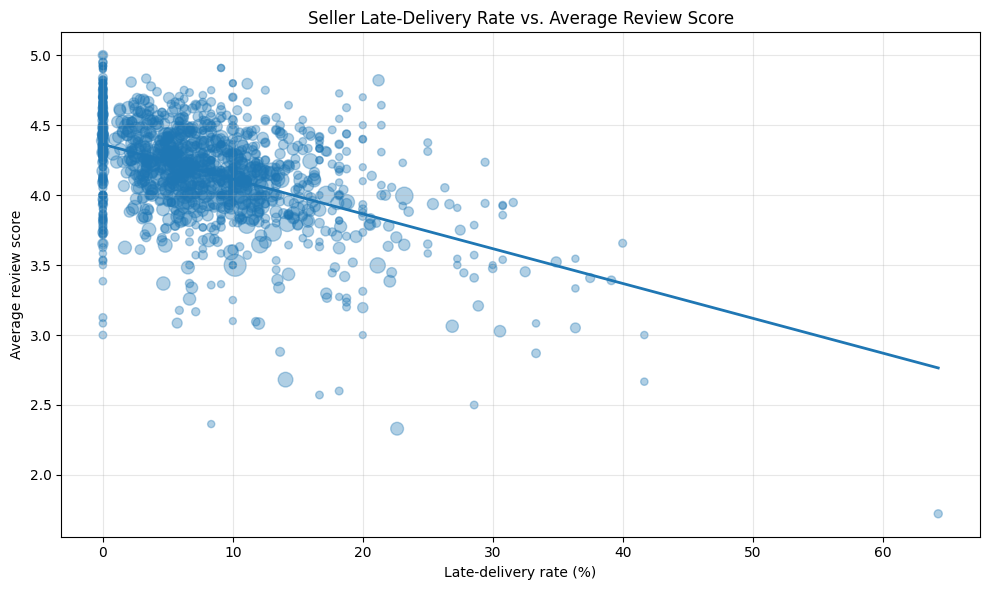

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Keep the validated seller-quality sample
seller_quality_viz = sellers[
    sellers["seller_average_review"].notna()
    & sellers["seller_late_delivery_rate"].notna()
    & (sellers["seller_reviewed_order_count"] >= 10)
    & (sellers["seller_delivery_order_count"] >= 10)
].copy()

print("Sellers in visualization sample:", len(seller_quality_viz))

# Convert late-delivery rate to percent for easier reading
seller_quality_viz["late_delivery_pct"] = (
    seller_quality_viz["seller_late_delivery_rate"] * 100
)

# Bubble sizes based on reviewed-order count
bubble_sizes = np.sqrt(seller_quality_viz["seller_reviewed_order_count"]) * 8

# Simple fitted trend line
x = seller_quality_viz["late_delivery_pct"]
y = seller_quality_viz["seller_average_review"]
coef = np.polyfit(x, y, 1)
trend_x = np.linspace(x.min(), x.max(), 200)
trend_y = coef[0] * trend_x + coef[1]

plt.figure(figsize=(10, 6))
plt.scatter(
    seller_quality_viz["late_delivery_pct"],
    seller_quality_viz["seller_average_review"],
    s=bubble_sizes,
    alpha=0.35
)

plt.plot(trend_x, trend_y, linewidth=2)

plt.title("Seller Late-Delivery Rate vs. Average Review Score")
plt.xlabel("Late-delivery rate (%)")
plt.ylabel("Average review score")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

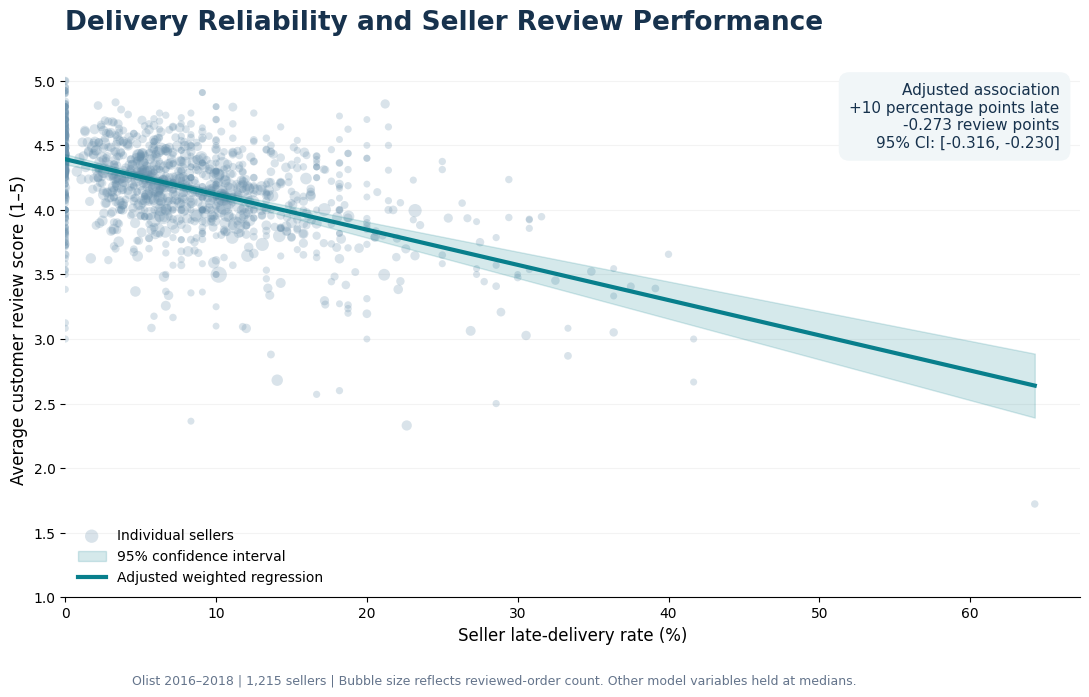

Sellers: 1,215
10-percentage-point adjusted effect: -0.2728
Model R²: 0.2497


In [7]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# Use the same seller eligibility rules as the validated model
d = sellers[
    (sellers["seller_reviewed_order_count"] >= 10) &
    (sellers["seller_delivery_order_count"] >= 10)
].copy()

d["log_product_count"] = np.log1p(d["seller_product_count"])
d["seller_log_order_count"] = np.log1p(d["seller_order_count"])
d = d.dropna(subset=[
    "seller_average_review", "seller_late_delivery_rate",
    "log_product_count", "seller_category_count",
    "seller_log_order_count", "seller_reviewed_order_count"
])

# Reproduce adjusted seller-quality regression
model = smf.wls(
    "seller_average_review ~ seller_late_delivery_rate "
    "+ log_product_count + seller_category_count "
    "+ seller_log_order_count",
    data=d,
    weights=d["seller_reviewed_order_count"]
).fit(cov_type="HC3")

# Adjusted predictions: other characteristics held at medians
x = np.linspace(0, d["seller_late_delivery_rate"].max(), 250)
reference = pd.DataFrame({
    "seller_late_delivery_rate": x,
    "log_product_count": d["log_product_count"].median(),
    "seller_category_count": d["seller_category_count"].median(),
    "seller_log_order_count": d["seller_log_order_count"].median()
})

pred = model.get_prediction(reference).summary_frame(alpha=0.05)

# Chart
fig, ax = plt.subplots(figsize=(11, 7))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

sizes = np.clip(
    12 + 4 * np.sqrt(d["seller_reviewed_order_count"]),
    18, 160
)

ax.scatter(
    d["seller_late_delivery_rate"] * 100,
    d["seller_average_review"],
    s=sizes, color="#6B91AC", alpha=0.25,
    edgecolors="none", label="Individual sellers"
)

ax.fill_between(
    x * 100,
    pred["mean_ci_lower"].to_numpy(),
    pred["mean_ci_upper"].to_numpy(),
    color="#087F8C", alpha=0.17,
    label="95% confidence interval"
)

ax.plot(
    x * 100,
    pred["mean"].to_numpy(),
    color="#087F8C", linewidth=3,
    label="Adjusted weighted regression"
)

effect = model.params["seller_late_delivery_rate"] * 0.10
ci = model.conf_int().loc["seller_late_delivery_rate"] * 0.10

ax.text(
    0.98, 0.96,
    f"Adjusted association\n"
    f"+10 percentage points late\n"
    f"{effect:+.3f} review points\n"
    f"95% CI: [{ci.iloc[0]:+.3f}, {ci.iloc[1]:+.3f}]",
    transform=ax.transAxes,
    ha="right", va="top",
    fontsize=11, color="#17324D",
    bbox=dict(
        boxstyle="round,pad=0.7",
        facecolor="#F1F6F8",
        edgecolor="none"
    )
)

ax.set_title(
    "Delivery Reliability and Seller Review Performance",
    loc="left", fontsize=19,
    color="#17324D", weight="bold", pad=23
)

ax.set_xlabel("Seller late-delivery rate (%)", fontsize=12)
ax.set_ylabel("Average customer review score (1–5)", fontsize=12)

ax.set_xlim(0, d["seller_late_delivery_rate"].max() * 100 + 3)
ax.set_ylim(1, 5.15)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)
ax.legend(loc="lower left", frameon=False, fontsize=10)

fig.text(
    0.125, 0.015,
    f"Olist 2016–2018 | {len(d):,} sellers | "
    "Bubble size reflects reviewed-order count. "
    "Other model variables held at medians.",
    fontsize=9, color="#64748B"
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

fig.savefig(
    OUTPUT / "seller_delivery_reliability_reviews.png",
    dpi=300, bbox_inches="tight"
)
fig.savefig(
    OUTPUT / "seller_delivery_reliability_reviews.svg",
    bbox_inches="tight"
)

plt.show()

print(f"Sellers: {len(d):,}")
print(f"10-percentage-point adjusted effect: {effect:.4f}")
print(f"Model R²: {model.rsquared:.4f}")


### Seller Delivery Reliability and Review Performance

This figure shows the validated relationship between seller late-delivery rate and average customer review score among sellers with at least 10 reviewed orders and 10 delivery observations.

The adjusted weighted regression indicates a clear negative association: a 10-percentage-point increase in seller late-delivery rate is associated with an estimated **0.273-point decrease** in average review score (95% CI: **-0.316 to -0.230**). The model explained about **25.0%** of the variation in seller average review scores (**R² = 0.2497**).

**Interpretation:** Sellers with less reliable delivery performance tend to receive lower customer ratings. This supports the broader customer-level findings and suggests that delivery reliability is an important part of seller quality. However, this is still an associational result, so it should not be interpreted as proof that delivery performance alone causes lower reviews.

# Seller Performance by State

seller_state  sellers  median_sales  mean_review  mean_late
          SP      750        100.99         4.14       9.00
          PR      133        130.85         4.24       5.72
          MG      109        111.53         4.15       6.59
          RJ       68        121.20         4.18       7.84
          SC       54        137.84         4.17       9.12
          RS       40        153.91         4.27       6.08


/tmp/ipykernel_2686/1617586855.py:154: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.04, 0.065, 1, 0.91])


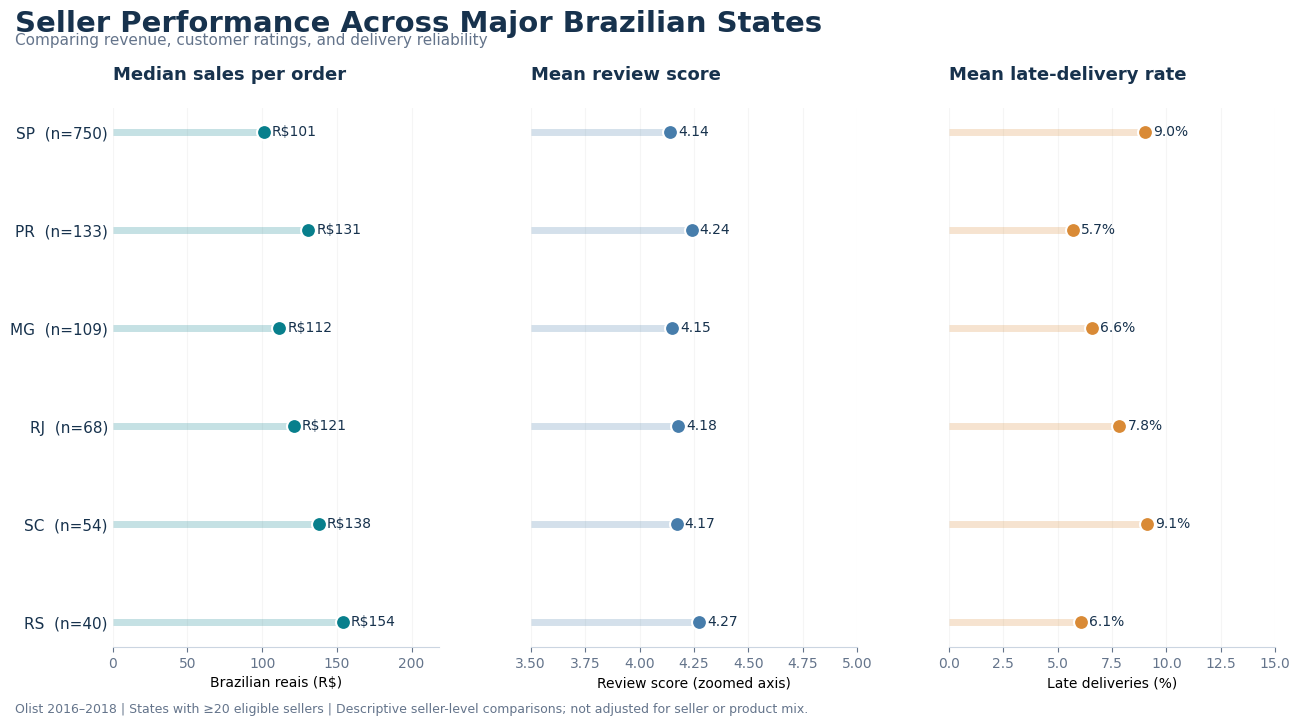

In [8]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the validated seller-quality eligibility criteria
geo = sellers[
    (sellers["seller_reviewed_order_count"] >= 10) &
    (sellers["seller_delivery_order_count"] >= 10) &
    (sellers["seller_order_count"] >= 10)
].copy()

geo = geo.dropna(subset=[
    "seller_state",
    "seller_total_sales",
    "seller_order_count",
    "seller_average_review",
    "seller_late_delivery_rate"
])

# Revenue per seller order (item-price revenue, not profit)
geo["sales_per_order"] = (
    geo["seller_total_sales"] / geo["seller_order_count"]
)
geo["late_pct"] = geo["seller_late_delivery_rate"] * 100

# Seller-level summary by state
state_summary = (
    geo.groupby("seller_state")
    .agg(
        sellers=("seller_id", "nunique"),
        median_sales=("sales_per_order", "median"),
        mean_review=("seller_average_review", "mean"),
        mean_late=("late_pct", "mean")
    )
    .reset_index()
)

# Only show states with at least 20 qualifying sellers
state_summary = (
    state_summary[state_summary["sellers"] >= 20]
    .sort_values("sellers", ascending=False)
    .reset_index(drop=True)
)

print(state_summary.round(2).to_string(index=False))

# Colors and layout
navy = "#17324D"
teal = "#087F8C"
orange = "#D98A36"
blue = "#477DAB"

fig, axes = plt.subplots(
    1, 3, figsize=(15, 7), sharey=True,
    gridspec_kw={"wspace": 0.28}
)

fig.patch.set_facecolor("white")

y = np.arange(len(state_summary))
labels = [
    f"{row.seller_state}  (n={row.sellers:,})"
    for row in state_summary.itertuples()
]

metrics = [
    ("median_sales", "Median sales per order", teal, "R${:,.0f}", 0),
    ("mean_review", "Mean review score", blue, "{:.2f}", 3.5),
    ("mean_late", "Mean late-delivery rate", orange, "{:.1f}%", 0)
]

for i, (column, heading, color, fmt, baseline) in enumerate(metrics):
    ax = axes[i]
    values = state_summary[column].to_numpy()

    ax.set_facecolor("white")

    # Horizontal lollipop chart
    ax.hlines(
        y, baseline, values,
        color=color, alpha=0.23, linewidth=5
    )
    ax.scatter(
        values, y,
        s=115, color=color, zorder=3,
        edgecolors="white", linewidth=1.5
    )

    ax.set_title(
        heading, loc="left",
        fontsize=13, fontweight="bold",
        color=navy, pad=20
    )

    # Explicit axis ranges
    if column == "median_sales":
        ax.set_xlim(0, values.max() * 1.42)
        ax.set_xlabel("Brazilian reais (R$)")
    elif column == "mean_review":
        ax.set_xlim(3.5, 5.0)
        ax.set_xlabel("Review score (zoomed axis)")
    else:
        ax.set_xlim(0, max(15, values.max() * 1.35))
        ax.set_xlabel("Late deliveries (%)")

    # Value labels
    xmin, xmax = ax.get_xlim()
    offset = (xmax - xmin) * 0.025

    for j, value in enumerate(values):
        ax.text(
            value + offset, j,
            fmt.format(value),
            va="center", ha="left",
            fontsize=10, color=navy,
            fontweight="medium"
        )

    ax.set_yticks(y)

    if i == 0:
        ax.set_yticklabels(labels, fontsize=11, color=navy)
        ax.tick_params(axis="y", length=0, labelleft=True)
    else:
        ax.tick_params(axis="y", length=0, labelleft=False)

    ax.grid(axis="x", alpha=0.12)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#CBD5E1")
    ax.tick_params(axis="x", colors="#64748B")

axes[0].invert_yaxis()

fig.suptitle(
    "Seller Performance Across Major Brazilian States",
    fontsize=21, fontweight="bold",
    color=navy, x=0.06, ha="left", y=1.02
)

fig.text(
    0.06, 0.97,
    "Comparing revenue, customer ratings, and delivery reliability",
    fontsize=11, color="#64748B"
)

fig.text(
    0.06, 0.015,
    "Olist 2016–2018 | States with ≥20 eligible sellers | "
    "Descriptive seller-level comparisons; not adjusted for seller or product mix.",
    fontsize=9, color="#64748B"
)

plt.tight_layout(rect=[0.04, 0.065, 1, 0.91])

fig.savefig(
    OUTPUT / "seller_geographic_performance.png",
    dpi=300, bbox_inches="tight"
)
fig.savefig(
    OUTPUT / "seller_geographic_performance.svg",
    bbox_inches="tight"
)

plt.show()



### Figure 3 — Seller Performance Across Brazilian States

Seller performance varied across the six states with at least 20 eligible sellers.

- **Rio Grande do Sul (RS)** had the highest median sales per order (R$153.91) and highest mean review score (4.27).

- **Paraná (PR)** had the lowest mean late-delivery rate (5.72%).

- **Santa Catarina (SC)** had the highest mean late-delivery rate (9.12%).

- **São Paulo (SP)** represented the largest group of eligible sellers (750), with median sales per order of R$100.99.

**Business interpretation:** Geographic comparisons reveal differences in seller revenue and service performance. These metrics could help marketplace managers identify regions for further investigation and operational monitoring.

**Limitation:** These comparisons are descriptive, with each qualifying seller contributing equally to the state averages. They do not account for differences in product mix, seller size, or other characteristics. The observed differences should not be interpreted as statistically established geographic effects or causal relationships.


# Delivery Delays and Customer Dissatisfaction

Customer orders analyzed: 95,830


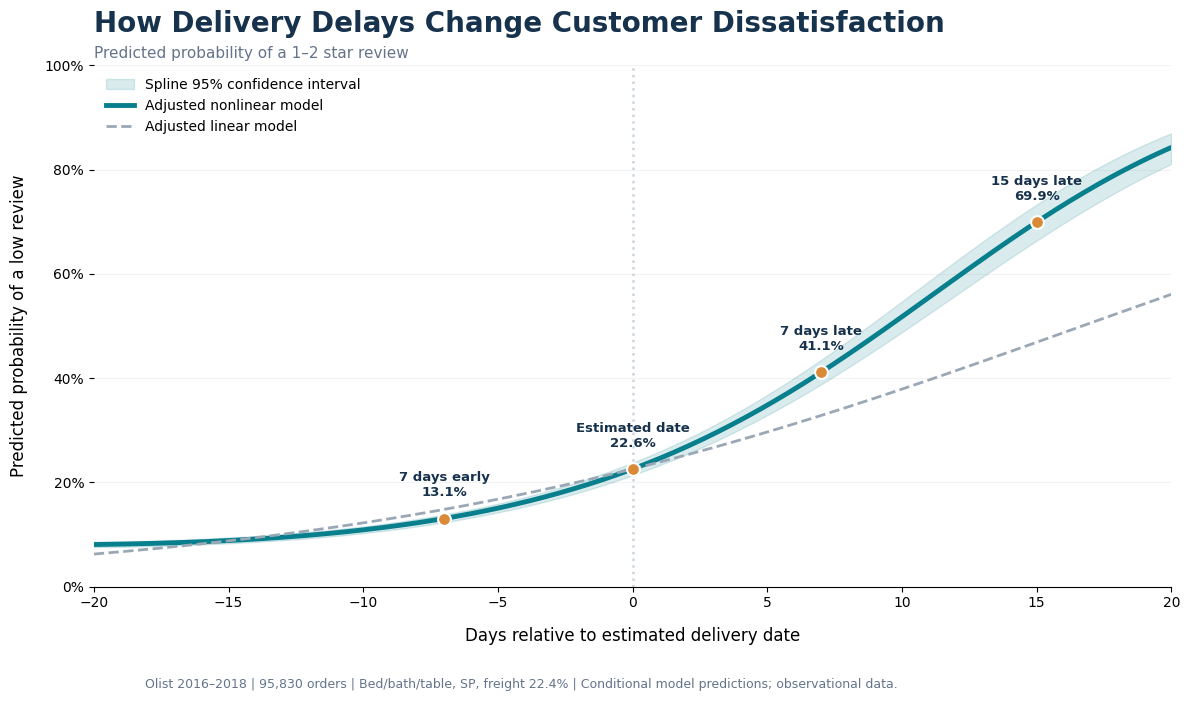


Predicted low-review probabilities:
-7 days: 13.06%
+0 days: 22.55%
+7 days: 41.13%
+15 days: 69.93%

Linear AIC: 66,614.26
Spline AIC: 64,896.69


In [9]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from matplotlib.ticker import PercentFormatter
from pathlib import Path

ROOT = Path("/content/CS690_Capstone")
OUTPUT = ROOT / "06_outputs/figures"
OUTPUT.mkdir(parents=True, exist_ok=True)

# Load the validated customer dataset
customer = pd.read_csv(
    ROOT / "02_data/processed/customer_experience.csv"
)

# Reproduce the Notebook 10–11 modeling sample
d = customer[
    [
        "review_score", "delivery_delay_days",
        "freight_percentage", "primary_category",
        "customer_state"
    ]
].replace([np.inf, -np.inf], np.nan)

d = d.dropna(subset=[
    "review_score", "delivery_delay_days", "freight_percentage"
]).copy()

d["low_review"] = (d["review_score"] <= 2).astype(int)
d["log_freight_percentage"] = np.log1p(d["freight_percentage"])
d["primary_category"] = d["primary_category"].fillna("Unknown")

category_counts = d["primary_category"].value_counts()
state_counts = d["customer_state"].value_counts()

d["category_group"] = np.where(
    d["primary_category"].isin(category_counts[category_counts >= 500].index),
    d["primary_category"], "Other"
)
d["state_group"] = np.where(
    d["customer_state"].isin(state_counts[state_counts >= 500].index),
    d["customer_state"], "Other"
)

print(f"Customer orders analyzed: {len(d):,}")

# Fit adjusted linear and nonlinear models
controls = (
    " + log_freight_percentage"
    " + C(category_group) + C(state_group)"
)

linear = smf.glm(
    "low_review ~ delivery_delay_days" + controls,
    data=d, family=sm.families.Binomial()
).fit(cov_type="HC3", maxiter=100)

spline = smf.glm(
    "low_review ~ bs(delivery_delay_days, df=4, degree=3)" + controls,
    data=d, family=sm.families.Binomial()
).fit(cov_type="HC3", maxiter=100)

# Predict for the same reference order used in validation
delay_range = np.linspace(-20, 20, 300)
median_freight = d["freight_percentage"].median()

reference = pd.DataFrame({
    "delivery_delay_days": delay_range,
    "log_freight_percentage": np.log1p(median_freight),
    "category_group": "bed_bath_table",
    "state_group": "SP"
})

linear_y = linear.predict(reference)

prediction = spline.get_prediction(reference).summary_frame(alpha=0.05)
spline_y = prediction["mean"].to_numpy()
lower = prediction["mean_ci_lower"].to_numpy()
upper = prediction["mean_ci_upper"].to_numpy()

# Styling
navy = "#17324D"
teal = "#087F8C"
orange = "#D98A36"
grey = "#9AA8B5"

fig, ax = plt.subplots(figsize=(12, 7))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Confidence interval
ax.fill_between(
    delay_range, lower, upper,
    color=teal, alpha=0.15,
    label="Spline 95% confidence interval"
)

# Main spline prediction
ax.plot(
    delay_range, spline_y,
    color=teal, linewidth=3.5,
    label="Adjusted nonlinear model"
)

# Original linear model
ax.plot(
    delay_range, linear_y,
    color=grey, linewidth=2,
    linestyle="--",
    label="Adjusted linear model"
)

# Reference line for estimated delivery date
ax.axvline(
    0, color="#CBD5E1",
    linestyle=":", linewidth=1.8
)

# Annotate important scenarios
scenarios = [-7, 0, 7, 15]
scenario_data = pd.DataFrame({
    "delivery_delay_days": scenarios,
    "log_freight_percentage": np.log1p(median_freight),
    "category_group": "bed_bath_table",
    "state_group": "SP"
})
scenario_probs = spline.predict(scenario_data)

for day, probability in zip(scenarios, scenario_probs):
    ax.scatter(
        day, probability, s=85,
        color=orange, edgecolor="white",
        linewidth=1.5, zorder=5
    )

    label = (
        "Estimated date" if day == 0
        else f"{abs(day)} days {'early' if day < 0 else 'late'}"
    )

    ax.annotate(
        f"{label}\n{probability:.1%}",
        xy=(day, probability),
        xytext=(0, 16),
        textcoords="offset points",
        ha="center",
        fontsize=9.5,
        fontweight="bold",
        color=navy
    )

ax.set_title(
    "How Delivery Delays Change Customer Dissatisfaction",
    fontsize=20, fontweight="bold",
    color=navy, loc="left", pad=24
)

ax.text(
    0, 1.015,
    "Predicted probability of a 1–2 star review",
    transform=ax.transAxes,
    fontsize=11, color="#64748B"
)

ax.set_xlabel(
    "Days relative to estimated delivery date",
    fontsize=12, labelpad=12
)
ax.set_ylabel(
    "Predicted probability of a low review",
    fontsize=12, labelpad=12
)

ax.set_xlim(-20, 20)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1))

ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)

ax.legend(
    loc="upper left", frameon=False,
    fontsize=10
)

fig.text(
    0.125, 0.01,
    f"Olist 2016–2018 | {len(d):,} orders | "
    f"Bed/bath/table, SP, freight {median_freight:.1f}% | "
    "Conditional model predictions; observational data.",
    fontsize=9, color="#64748B"
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

fig.savefig(
    OUTPUT / "customer_delivery_delay_risk.png",
    dpi=300, bbox_inches="tight"
)
fig.savefig(
    OUTPUT / "customer_delivery_delay_risk.svg",
    bbox_inches="tight"
)

plt.show()

# Verify against the previous validation results
print("\nPredicted low-review probabilities:")
for day, probability in zip(scenarios, scenario_probs):
    print(f"{day:+d} days: {probability:.2%}")

print(f"\nLinear AIC: {linear.aic:,.2f}")
print(f"Spline AIC: {spline.aic:,.2f}")



### Figure 4 — Delivery Delays and Customer Dissatisfaction

The adjusted spline model shows a nonlinear relationship between delivery delays and customer dissatisfaction.

For a reference order in the bed/bath/table category, delivered to São Paulo with median freight percentage, the predicted probability of a low review increased from 22.55% on the estimated delivery date to 41.13% at seven days late and 69.93% at fifteen days late.

The spline model provided a better fit than the linear logistic model (AIC: 64,896.69 versus 66,614.26), indicating that a constant linear relationship does not adequately describe delivery-related dissatisfaction.

**Business interpretation:** Preventing severe delivery delays should be a priority for marketplace operations. Monitoring average delivery time alone may overlook orders associated with particularly high dissatisfaction.

**Research connection:** Ravula (2022) similarly found that customers respond more negatively to late deliveries than positively to early deliveries.

**Limitation:** These probabilities are conditional model predictions for a specific order profile, not observed population-wide rates. The results demonstrate associations rather than causation.


# Product Categories and Customer Dissatisfaction

Category comparisons: 26
FDR-significant comparisons: 9

Full adjusted category results:
                       category  orders  odds_ratio  ci_lower  ci_upper  q_value  fdr_significant
               office_furniture    1234      2.0238    1.7193    2.3822   0.0000             True
                 bed_bath_table    9145      1.3266    1.2062    1.4590   0.0000             True
                furniture_decor    6162      1.2585    1.1335    1.3972   0.0001             True
          computers_accessories    6488      1.2509    1.1279    1.3872   0.0001             True
                     stationery    2228      0.7207    0.6097    0.8518   0.0006             True
                        Unknown    1324      1.3589    1.1460    1.6114   0.0018             True
            luggage_accessories    1007      0.6535    0.5100    0.8373   0.0029             True
                  health_beauty    8577      0.8746    0.7904    0.9678   0.0285             True
                 sports_leisu

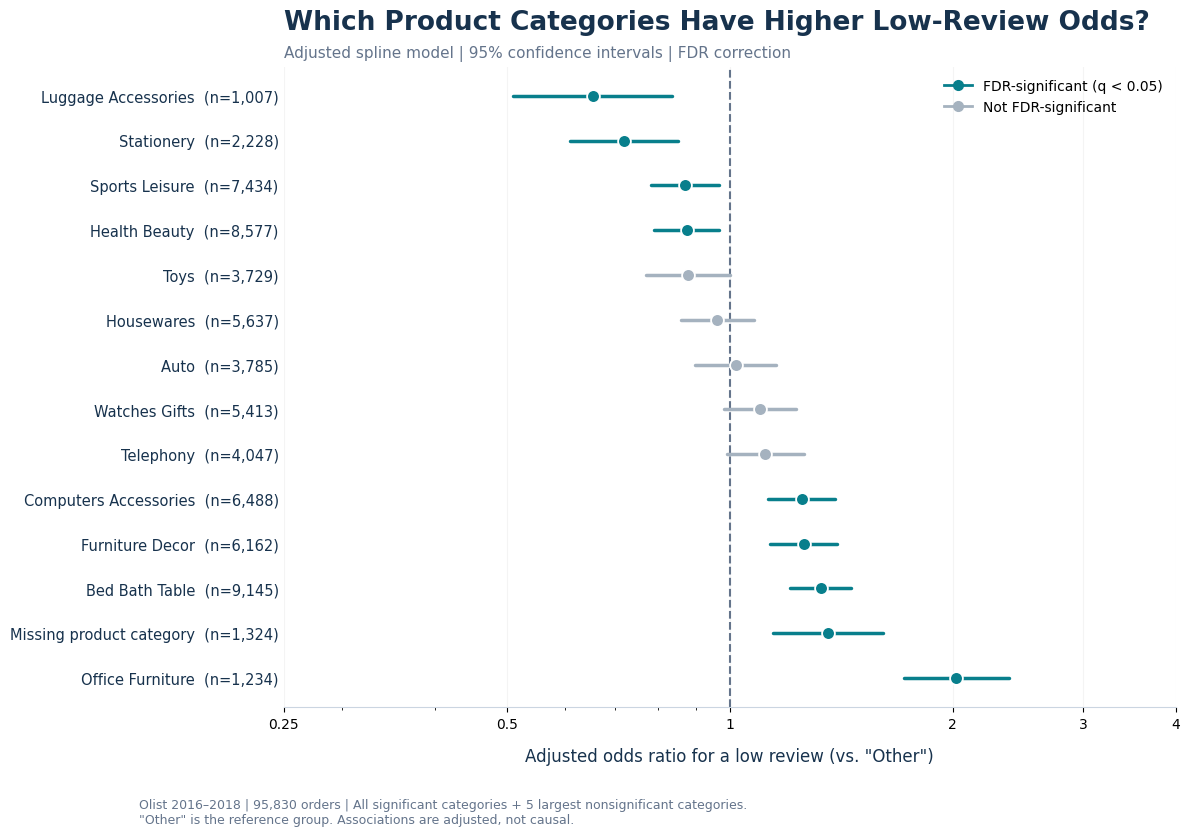

In [14]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests
from matplotlib.lines import Line2D

# Reuse the validated adjusted spline model from Figure 4.
# Run the Figure 4 model cell first if restarting Colab.

category_terms = [
    term for term in spline.params.index
    if term.startswith("C(category_group)[T.")
]

rows = []
ci = spline.conf_int()
counts = d["category_group"].value_counts()

for term in category_terms:
    category = term.split("[T.", 1)[1].rsplit("]", 1)[0]

    rows.append({
        "category": category,
        "orders": int(counts.get(category, 0)),
        "odds_ratio": np.exp(spline.params[term]),
        "ci_lower": np.exp(ci.loc[term, 0]),
        "ci_upper": np.exp(ci.loc[term, 1]),
        "p_value": spline.pvalues[term]
    })

category_results = pd.DataFrame(rows)

# Correct all category comparisons together
reject, q_values, _, _ = multipletests(
    category_results["p_value"],
    alpha=0.05,
    method="fdr_bh"
)

category_results["fdr_significant"] = reject
category_results["q_value"] = q_values

# Verify expected model structure
assert len(category_results) == 26, "Unexpected category comparison count."

print("Category comparisons:", len(category_results))
print("FDR-significant comparisons:", reject.sum())

# Display every comparison in the output table
print("\nFull adjusted category results:")
print(
    category_results.sort_values("q_value")[
        ["category", "orders", "odds_ratio",
         "ci_lower", "ci_upper", "q_value",
         "fdr_significant"]
    ].round(4).to_string(index=False)
)

# All significant categories + 5 largest nonsignificant
significant = category_results[
    category_results["fdr_significant"]
]

additional = (
    category_results[
        ~category_results["fdr_significant"]
    ]
    .sort_values("orders", ascending=False)
    .head(5)
)

plot_data = (
    pd.concat([significant, additional])
    .sort_values("odds_ratio", ascending=True)
    .reset_index(drop=True)
)

# Professional styling
navy = "#17324D"
teal = "#087F8C"
grey = "#A5B2BF"

fig, ax = plt.subplots(figsize=(12, 8.5))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

y = np.arange(len(plot_data))

# Reference: OR = 1 means equal odds to "Other"
ax.axvline(
    1, color="#64748B",
    linestyle="--", linewidth=1.5,
    zorder=1
)

for i, row in plot_data.iterrows():
    color = teal if row["fdr_significant"] else grey

    ax.plot(
        [row["ci_lower"], row["ci_upper"]],
        [i, i],
        color=color, linewidth=2.5,
        solid_capstyle="round", zorder=2
    )

    ax.scatter(
        row["odds_ratio"], i,
        s=85, color=color,
        edgecolors="white",
        linewidth=1.3, zorder=3
    )

# Format category labels
def label_category(value):
    if value == "Unknown":
        return "Missing product category"
    return value.replace("_", " ").title()

labels = [
    f"{label_category(row.category)}  (n={row.orders:,})"
    for row in plot_data.itertuples()
]

ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=10.5, color=navy)
ax.invert_yaxis()

ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 3, 4])
ax.set_xticklabels(["0.25", "0.5", "1", "2", "3", "4"])


ax.set_xlim(
    min(0.25, plot_data["ci_lower"].min() * 0.85),
    max(4, plot_data["ci_upper"].max() * 1.15)
)

ax.set_xlabel(
    'Adjusted odds ratio for a low review (vs. "Other")',
    fontsize=12, color=navy, labelpad=12
)

ax.set_title(
    "Which Product Categories Have Higher Low-Review Odds?",
    fontsize=19, fontweight="bold",
    color=navy, loc="left", pad=27
)

ax.text(
    0, 1.015,
    "Adjusted spline model | 95% confidence intervals | FDR correction",
    transform=ax.transAxes,
    fontsize=11, color="#64748B"
)

ax.grid(axis="x", alpha=0.13)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color("#CBD5E1")

legend = [
    Line2D([0], [0], marker="o", color=teal,
           linewidth=2, markersize=7,
           label="FDR-significant (q < 0.05)"),
    Line2D([0], [0], marker="o", color=grey,
           linewidth=2, markersize=7,
           label="Not FDR-significant")
]

ax.legend(
    handles=legend,
    loc="upper right",
    frameon=False,
    fontsize=10
)

fig.text(
    0.12, 0.025,
    "Olist 2016–2018 | 95,830 orders | "
    "All significant categories + 5 largest nonsignificant categories.\n"
    '"Other" is the reference group. '
    "Associations are adjusted, not causal.",
    fontsize=9, color="#64748B"
)

plt.tight_layout(rect=[0, 0.075, 1, 1])

fig.savefig(
    OUTPUT / "customer_product_category_forest.png",
    dpi=300, bbox_inches="tight"
)
fig.savefig(
    OUTPUT / "customer_product_category_forest.svg",
    bbox_inches="tight"
)

plt.show()



### Figure 5 — Product Categories and Low-Review Odds

The adjusted spline model identified 9 statistically significant category comparisons out of 26 after Benjamini–Hochberg FDR correction.

Office furniture had the highest adjusted odds of receiving a low review (OR = 2.02, 95% CI: 1.72–2.38), followed by several other categories, including bed/bath/table and furniture/decor. Stationery and luggage/accessories showed significantly lower odds.

**Business interpretation:** Customer dissatisfaction differs across product categories, suggesting that marketplace managers should investigate category-specific service and fulfillment problems.

**Limitations:** Results are relative to the grouped "Other" reference category and do not establish causation. The significant "Unknown" group represents missing product-category information, not a distinct product type.


# Customer Geography and Low-Review Odds

State comparisons: 17
FDR-significant comparisons: 6

Full adjusted state results:
state  orders  odds_ratio  ci_lower  ci_upper  q_value  fdr_significant
   SP   40267      0.7033    0.6316    0.7831   0.0000             True
   PR    4900      0.7917    0.6895    0.9091   0.0079             True
   RS    5326      0.8079    0.7069    0.9233   0.0099             True
   ES    1969      0.7836    0.6589    0.9319   0.0206             True
   SC    3520      0.8180    0.7086    0.9442   0.0206             True
   MG   11286      0.8559    0.7608    0.9627   0.0270             True
   MS     699      0.7937    0.6199    1.0163   0.1626            False
   GO    1946      0.8682    0.7305    1.0319   0.2313            False
   PA     933      1.1626    0.9475    1.4264   0.2793            False
   CE    1273      0.8721    0.7190    1.0576   0.2793            False
   DF    2070      0.9074    0.7700    1.0694   0.3810            False
Other    2516      0.9284    0.7963    1.0825   0.486

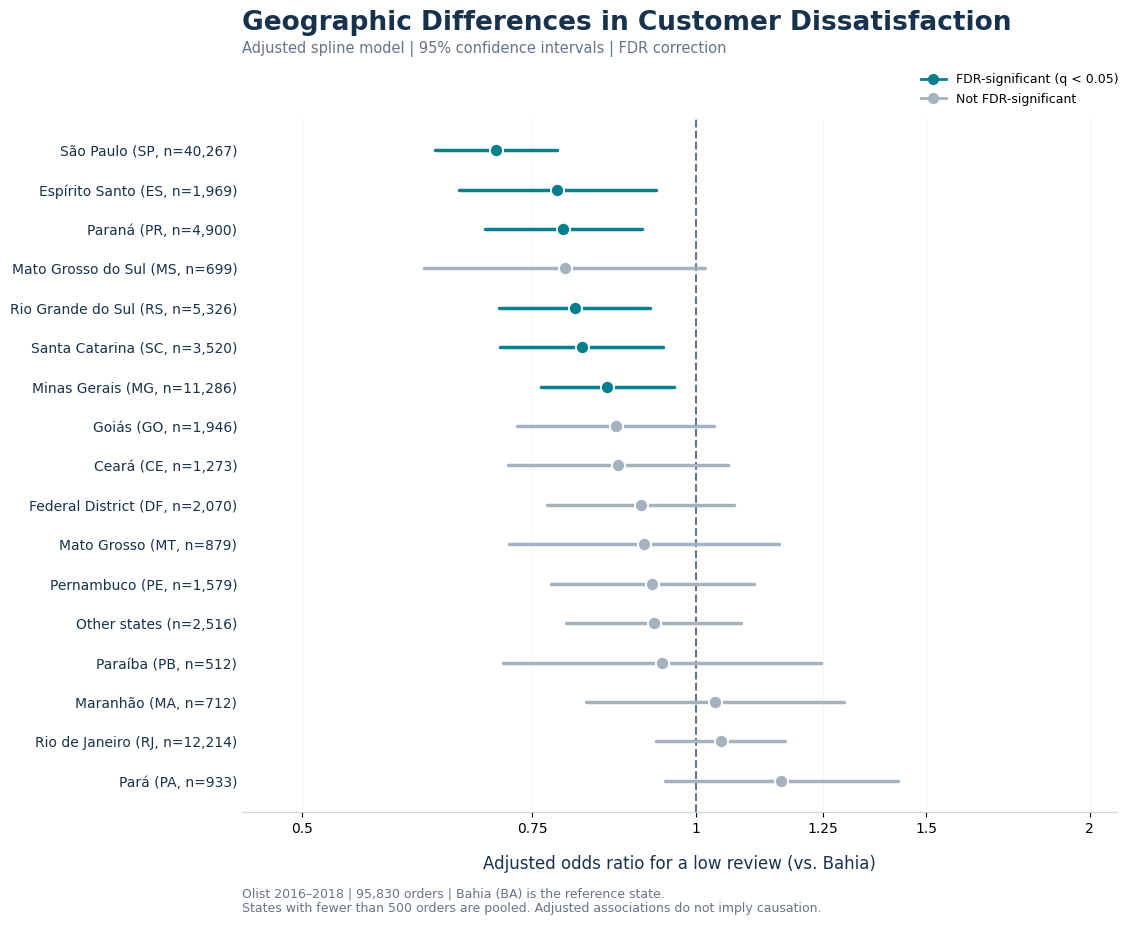

In [15]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import NullLocator, NullFormatter
from statsmodels.stats.multitest import multipletests

# Extract adjusted customer-state comparisons
state_terms = [
    term for term in spline.params.index
    if term.startswith("C(state_group)[T.")
]

ci = spline.conf_int()
counts = d["state_group"].value_counts()

rows = []

for term in state_terms:
    state = term.split("[T.", 1)[1].rsplit("]", 1)[0]

    rows.append({
        "state": state,
        "orders": int(counts.get(state, 0)),
        "odds_ratio": np.exp(spline.params[term]),
        "ci_lower": np.exp(ci.loc[term, 0]),
        "ci_upper": np.exp(ci.loc[term, 1]),
        "p_value": spline.pvalues[term]
    })

state_results = pd.DataFrame(rows)

# Benjamini-Hochberg FDR correction
reject, q_values, _, _ = multipletests(
    state_results["p_value"],
    alpha=0.05,
    method="fdr_bh"
)

state_results["fdr_significant"] = reject
state_results["q_value"] = q_values

print("State comparisons:", len(state_results))
print("FDR-significant comparisons:", reject.sum())

print("\nFull adjusted state results:")
print(
    state_results.sort_values("q_value")[
        ["state", "orders", "odds_ratio",
         "ci_lower", "ci_upper", "q_value",
         "fdr_significant"]
    ].round(4).to_string(index=False)
)

# Plot every state comparison
plot_data = (
    state_results
    .sort_values("odds_ratio")
    .reset_index(drop=True)
)

# State display names
state_names = {
    "BA": "Bahia",
    "SP": "São Paulo",
    "PR": "Paraná",
    "RJ": "Rio de Janeiro",
    "MG": "Minas Gerais",
    "RS": "Rio Grande do Sul",
    "SC": "Santa Catarina",
    "PE": "Pernambuco",
    "CE": "Ceará",
    "GO": "Goiás",
    "ES": "Espírito Santo",
    "PA": "Pará",
    "MA": "Maranhão",
    "MT": "Mato Grosso",
    "MS": "Mato Grosso do Sul",
    "PB": "Paraíba",
    "RN": "Rio Grande do Norte",
    "PI": "Piauí",
    "DF": "Federal District",
    "AL": "Alagoas",
    "SE": "Sergipe",
    "TO": "Tocantins",
    "AM": "Amazonas",
    "RO": "Rondônia",
    "AC": "Acre",
    "AP": "Amapá",
    "RR": "Roraima",
    "Other": "Other states (pooled)"
}

labels = [
    (
        f"{state_names.get(row.state, row.state)} "
        f"({row.state}, n={row.orders:,})"
        if row.state != "Other"
        else f"Other states (n={row.orders:,})"
    )
    for row in plot_data.itertuples()
]

# Colors
navy = "#17324D"
teal = "#087F8C"
grey = "#A5B2BF"

# Figure setup
fig, ax = plt.subplots(figsize=(12.5, 9.5))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

y = np.arange(len(plot_data))

# Reference line: odds ratio = 1
ax.axvline(
    1,
    color="#64748B",
    linestyle="--",
    linewidth=1.5,
    zorder=1
)

# Confidence intervals and point estimates
for i, row in plot_data.iterrows():
    color = teal if row["fdr_significant"] else grey

    ax.plot(
        [row["ci_lower"], row["ci_upper"]],
        [i, i],
        color=color,
        linewidth=2.5,
        solid_capstyle="round",
        zorder=2
    )

    ax.scatter(
        row["odds_ratio"],
        i,
        s=90,
        color=color,
        edgecolors="white",
        linewidth=1.3,
        zorder=3
    )

# State labels
ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=10, color=navy)
ax.invert_yaxis()

# Logarithmic odds-ratio axis
ax.set_xscale("log")

# Explicit major ticks and labels
major_ticks = [0.5, 0.75, 1, 1.25, 1.5, 2]
major_labels = ["0.5", "0.75", "1", "1.25", "1.5", "2"]

ax.set_xticks(major_ticks)
ax.set_xticklabels(major_labels)

# FIX: Remove unwanted minor ticks and scientific-notation labels
ax.xaxis.set_minor_locator(NullLocator())
ax.xaxis.set_minor_formatter(NullFormatter())

ax.set_xlim(
    min(0.45, plot_data["ci_lower"].min() * 0.9),
    max(2.1, plot_data["ci_upper"].max() * 1.1)
)

ax.set_xlabel(
    "Adjusted odds ratio for a low review (vs. Bahia)",
    fontsize=12,
    color=navy,
    labelpad=13
)

# Grid and axes
ax.grid(axis="x", alpha=0.13)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color("#CBD5E1")

# Legend
legend = [
    Line2D(
        [0], [0],
        marker="o",
        color=teal,
        linewidth=2,
        markersize=7,
        label="FDR-significant (q < 0.05)"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color=grey,
        linewidth=2,
        markersize=7,
        label="Not FDR-significant"
    )
]

fig.legend(
    handles=legend,
    loc="upper right",
    bbox_to_anchor=(0.97, 0.93),
    frameon=False,
    fontsize=9
)

# Title
fig.suptitle(
    "Geographic Differences in Customer Dissatisfaction",
    x=0.26,
    y=0.985,
    ha="left",
    fontsize=19,
    fontweight="bold",
    color=navy
)

# Subtitle
fig.text(
    0.26,
    0.94,
    "Adjusted spline model | 95% confidence intervals | FDR correction",
    fontsize=10.5,
    color="#64748B"
)

# Source and limitations
fig.text(
    0.26,
    0.035,
    f"Olist 2016–2018 | {len(d):,} orders | "
    "Bahia (BA) is the reference state.\n"
    "States with fewer than 500 orders are pooled. "
    "Adjusted associations do not imply causation.",
    fontsize=9,
    color="#64748B"
)

# Layout
fig.subplots_adjust(
    left=0.26,
    right=0.96,
    top=0.87,
    bottom=0.14
)

# Save final visualization
fig.savefig(
    OUTPUT / "customer_state_forest.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT / "customer_state_forest.svg",
    bbox_inches="tight"
)

plt.show()



### Figure 6 — Geographic Differences in Customer Dissatisfaction

The adjusted spline model identified 6 statistically significant customer-state comparisons out of 17 after Benjamini–Hochberg FDR correction.

Compared with Bahia (BA), São Paulo (SP) had significantly lower adjusted odds of receiving a low review (OR = 0.70, 95% CI: 0.63–0.78). Paraná, Rio Grande do Sul, Espírito Santo, Santa Catarina, and Minas Gerais also showed significantly lower odds.

Rio de Janeiro and Pará did not show statistically significant differences from Bahia after correction.

**Business interpretation:** Customer satisfaction varies geographically, suggesting that marketplaces could benefit from monitoring regional service performance and investigating areas with elevated dissatisfaction.

**Limitation:** These results account for delivery delay, freight percentage, and product category, but not every possible regional difference. They do not establish that geographic location causes dissatisfaction.


# Customer Model Coverage and Excluded Orders

Total orders: 99,441
Included in customer model: 95,830 (96.37%)
Excluded from customer model: 3,611 (3.63%)

Included orders with reviews: 95,830
Excluded orders with reviews: 2,843
Low-review rate — included: 12.77%
Low-review rate — excluded: 77.70%


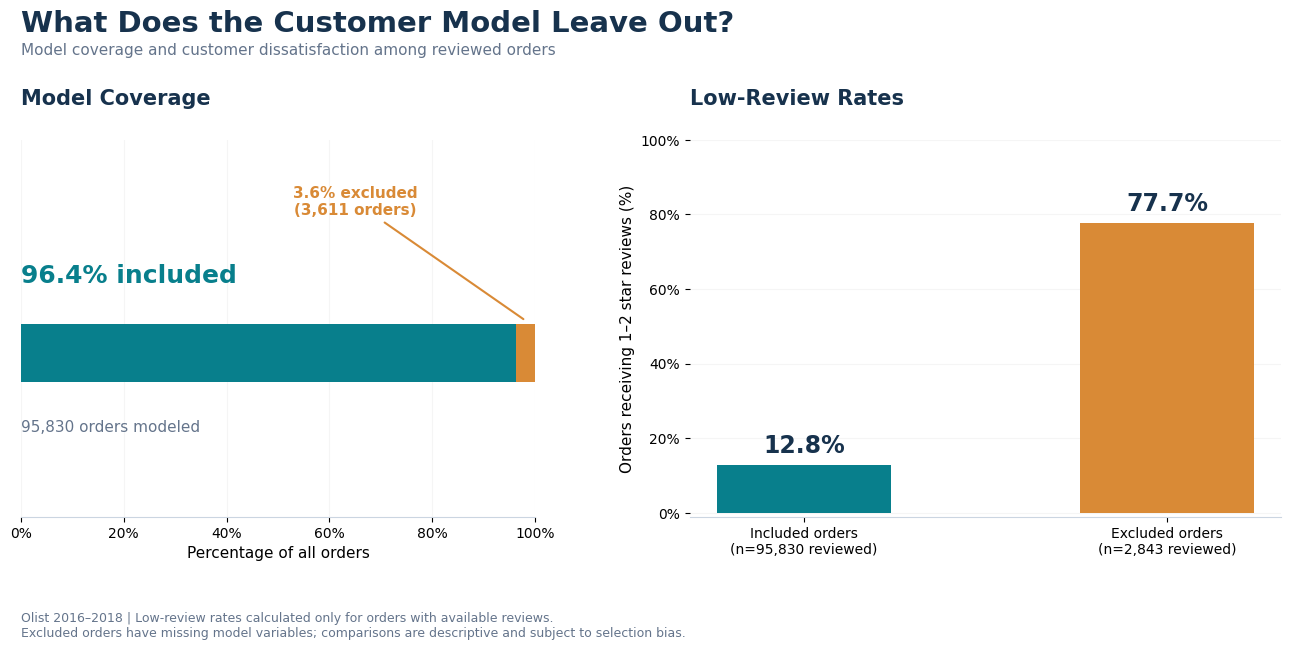

In [18]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.ticker import PercentFormatter

ROOT = Path("/content/CS690_Capstone")
OUTPUT = ROOT / "06_outputs/figures"
OUTPUT.mkdir(parents=True, exist_ok=True)

# Load original customer-experience table
customer = pd.read_csv(
    ROOT / "02_data/processed/customer_experience.csv"
)

# Same required variables used in the validated customer model
required = [
    "review_score",
    "delivery_delay_days",
    "freight_percentage"
]

data = customer[required].copy()

for col in required:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.replace([np.inf, -np.inf], np.nan)

# Identify modeled and excluded orders
included = data[required].notna().all(axis=1)
excluded = ~included
has_review = data["review_score"].notna()
low_review = data["review_score"] <= 2

n_total = len(data)
n_included = int(included.sum())
n_excluded = int(excluded.sum())

n_reviewed_included = int((included & has_review).sum())
n_reviewed_excluded = int((excluded & has_review).sum())

rate_included = (
    low_review[included & has_review].mean() * 100
)
rate_excluded = (
    low_review[excluded & has_review].mean() * 100
)

pct_included = n_included / n_total * 100
pct_excluded = n_excluded / n_total * 100

# Validate against Notebook 11
assert n_total == 99_441
assert n_included == 95_830
assert n_excluded == 3_611
assert n_reviewed_excluded == 2_843

print(f"Total orders: {n_total:,}")
print(f"Included in customer model: {n_included:,} ({pct_included:.2f}%)")
print(f"Excluded from customer model: {n_excluded:,} ({pct_excluded:.2f}%)")
print()
print(f"Included orders with reviews: {n_reviewed_included:,}")
print(f"Excluded orders with reviews: {n_reviewed_excluded:,}")
print(f"Low-review rate — included: {rate_included:.2f}%")
print(f"Low-review rate — excluded: {rate_excluded:.2f}%")

# Colors
navy = "#17324D"
teal = "#087F8C"
orange = "#D98A36"
muted = "#64748B"

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6.5),
    gridspec_kw={"width_ratios": [1, 1.15], "wspace": 0.28}
)

fig.patch.set_facecolor("white")

# --------------------------------------------------
# PANEL 1 — Customer-model coverage
# --------------------------------------------------
ax = axes[0]
ax.set_facecolor("white")

ax.barh(
    0, pct_included,
    height=0.23,
    color=teal
)

ax.barh(
    0, pct_excluded,
    left=pct_included,
    height=0.23,
    color=orange
)

ax.set_title(
    "Model Coverage",
    loc="left",
    fontsize=15,
    fontweight="bold",
    color=navy,
    pad=25
)

ax.text(
    0, 0.28,
    f"{pct_included:.1f}% included",
    fontsize=18,
    fontweight="bold",
    color=teal
)

ax.text(
    0, -0.31,
    f"{n_included:,} orders modeled",
    fontsize=11,
    color=muted
)

ax.annotate(
    f"{pct_excluded:.1f}% excluded\n({n_excluded:,} orders)",
    xy=(pct_included + pct_excluded / 2, 0.13),
    xytext=(65, 0.55),
    fontsize=11,
    fontweight="bold",
    color=orange,
    ha="center",
    arrowprops=dict(
        arrowstyle="-",
        color=orange,
        linewidth=1.5
    )
)

ax.set_xlim(0, 100)
ax.set_ylim(-0.65, 0.85)
ax.set_yticks([])
ax.set_xlabel("Percentage of all orders", fontsize=11)
ax.xaxis.set_major_formatter(PercentFormatter(100))

ax.grid(axis="x", alpha=0.12)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color("#CBD5E1")

# --------------------------------------------------
# PANEL 2 — Low-review rates
# --------------------------------------------------
ax = axes[1]
ax.set_facecolor("white")

groups = [
    f"Included orders\n(n={n_reviewed_included:,} reviewed)",
    f"Excluded orders\n(n={n_reviewed_excluded:,} reviewed)"
]
rates = [rate_included, rate_excluded]
sample_sizes = [n_reviewed_included, n_reviewed_excluded]
colors = [teal, orange]

bars = ax.bar(
    groups, rates,
    color=colors,
    width=0.48,
    zorder=3
)

for bar, value, count in zip(bars, rates, sample_sizes):
    x = bar.get_x() + bar.get_width() / 2

    ax.text(
        x, value + 2,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=17,
        fontweight="bold",
        color=navy
    )



ax.set_title(
    "Low-Review Rates",
    loc="left",
    fontsize=15,
    fontweight="bold",
    color=navy,
    pad=25
)

ax.set_ylabel(
    "Orders receiving 1–2 star reviews (%)",
    fontsize=11
)

ax.set_ylim(-1, 100)
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.grid(axis="y", alpha=0.12)
ax.set_axisbelow(True)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color("#CBD5E1")

# Main title and subtitle
fig.suptitle(
    "What Does the Customer Model Leave Out?",
    fontsize=21,
    fontweight="bold",
    color=navy,
    x=0.07,
    y=0.99,
    ha="left"
)

fig.text(
    0.07, 0.92,
    "Model coverage and customer dissatisfaction among reviewed orders",
    fontsize=11,
    color=muted
)

fig.text(
    0.07, 0.025,
    "Olist 2016–2018 | Low-review rates calculated only for orders with available reviews.\n"
    "Excluded orders have missing model variables; comparisons are descriptive "
    "and subject to selection bias.",
    fontsize=9,
    color=muted
)

fig.subplots_adjust(
    left=0.07,
    right=0.97,
    top=0.79,
    bottom=0.21
)

fig.savefig(
    OUTPUT / "customer_model_coverage.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT / "customer_model_coverage.svg",
    bbox_inches="tight"
)

plt.show()



### Figure 7 — Customer Model Coverage and Excluded Orders

The customer model included 95,830 of 99,441 orders (96.37%), excluding 3,611 orders (3.63%) because of missing required variables.

Although the excluded group was relatively small, 77.70% of excluded orders with available reviews received low ratings (1–2 stars), compared with 12.77% of included orders.

**Business interpretation:** Customer dissatisfaction is particularly prevalent among orders excluded from the delivery-based model. Marketplace managers should monitor canceled, undelivered, and otherwise unsuccessful transactions separately to avoid overlooking serious customer-experience problems.

**Limitation:** Low-review percentages are calculated only among orders with available reviews. The differences are descriptive and do not establish why excluded orders received lower ratings. These orders are not adequately represented by the final customer model.
